# Criar características novas e comparar modelos
Neste notebook fazemos duas coisas:
1. Criamos características novas a partir das que já temos.
2. Treinamos vários modelos para ver qual funciona melhor, com e sem essas características novas.

**Passos:**
1. Preparar os dados
2. Trabalhar as características (escolher, criar, resumir)
3. Comparar modelos
4. Testar o melhor
5. Ver o que mais importa

**Nota:** os passos de preparação são feitos dentro de um "Pipeline" (uma cadeia de passos) e só com os dados de treino, para o modelo não "espreitar" o teste.

Correr o comando: `!pip install -q xgboost imbalanced-learn`.

## 1. Preparar os dados
Carregamos, limpamos e dividimos em treino e teste, como nos notebooks anteriores.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, f1_score, recall_score, precision_score, classification_report, confusion_matrix

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from pathlib import Path

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

cwd = Path.cwd().resolve()
repo_root = next((p for p in [cwd, *cwd.parents] if (p / "notebooks").is_dir()), cwd)
matches = list(repo_root.rglob("uci_malware_detection.csv"))

if not matches:
    raise FileNotFoundError(
        f"uci_malware_detection.csv was not found under {repo_root}. "
        "Place the file in the project folder or update the path."
    )

df = pd.read_csv(matches[0]).drop_duplicates().reset_index(drop=True)
print("Loaded:", matches[0])
feat_cols = [c for c in df.columns if c != 'Label']
feat_cols = [c for c in feat_cols if df[c].nunique() > 1]       # remove colunas constantes

X = df[feat_cols]
y = (df['Label'] == 'malicious').astype(int)                     # 1 = malicious, 0 = non-malicious

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print('Treino:', X_train.shape, '| Teste:', X_test.shape)
print('Classes no treino:', y_train.value_counts().to_dict(), '(0 = non-malicious, 1 = malicious)')

Loaded: D:\IAAC\grupo4-iaac\data\raw\uci_malware_detection.csv
Treino: (296, 503) | Teste: (75, 503)
Classes no treino: {1: 240, 0: 56} (0 = non-malicious, 1 = malicious)


## 2. Trabalhar as características
Cada passo aprende primeiro com os dados de treino e só depois é aplicado.

### 2.1 Escolher características
Tiramos as que quase nunca mudam e as que são cópias de outras.

In [2]:
class SelecionarFeatures(BaseEstimator, TransformerMixin):
    def __init__(self, min_freq=0.01):
        self.min_freq = min_freq

    def fit(self, X, y=None):
        freq = X.mean()
        keep = freq[(freq >= self.min_freq) & (freq <= 1 - self.min_freq)].index
        dup = X[keep].T.duplicated().values            # colunas idênticas
        self.cols_ = list(keep[~dup])
        return self

    def transform(self, X):
        return X[self.cols_]

sel = SelecionarFeatures().fit(X_train)
print('Features antes:', X_train.shape[1], '| depois da seleção:', len(sel.cols_))

Features antes: 503 | depois da seleção: 388


### 2.2 Criar características novas
Criamos 4 números novos que resumem cada amostra. Não usam a resposta (`Label`), por isso não há batota.

| Característica nova | O que significa |
|---|---|
| `n_ativas` | Quantas características estão ativas |
| `n_raras_ativas` | Quantas dessas são raras |
| `n_comuns_ativas` | Quantas são comuns |
| `prop_raras` | Que parte das ativas é rara |

In [3]:
class AdicionarFeatures(BaseEstimator, TransformerMixin):
    def __init__(self, limite_rara=0.05, limite_comum=0.5):
        self.limite_rara = limite_rara
        self.limite_comum = limite_comum

    def fit(self, X, y=None):
        freq = X.mean()
        self.raras_ = list(freq[freq < self.limite_rara].index)
        self.comuns_ = list(freq[freq >= self.limite_comum].index)
        return self

    def transform(self, X):
        out = X.copy()
        n = X.sum(axis=1)
        raras = X[self.raras_].sum(axis=1)
        out['n_ativas'] = n
        out['n_raras_ativas'] = raras
        out['n_comuns_ativas'] = X[self.comuns_].sum(axis=1)
        out['prop_raras'] = raras / n.replace(0, np.nan)
        out['prop_raras'] = out['prop_raras'].fillna(0)
        return out

demo = Pipeline([('sel', SelecionarFeatures()), ('fe', AdicionarFeatures())]).fit(X_train)
X_demo = demo.transform(X_train)
novas = ['n_ativas', 'n_raras_ativas', 'n_comuns_ativas', 'prop_raras']
print('Features após seleção + engineering:', X_demo.shape[1])
print(X_demo[novas].groupby(y_train.map({0: 'non-malicious', 1: 'malicious'})).mean().round(2))

Features após seleção + engineering: 392
               n_ativas  n_raras_ativas  n_comuns_ativas  prop_raras
Label                                                               
malicious         90.32            0.05            83.60        0.00
non-malicious    120.59           23.64            53.36        0.15


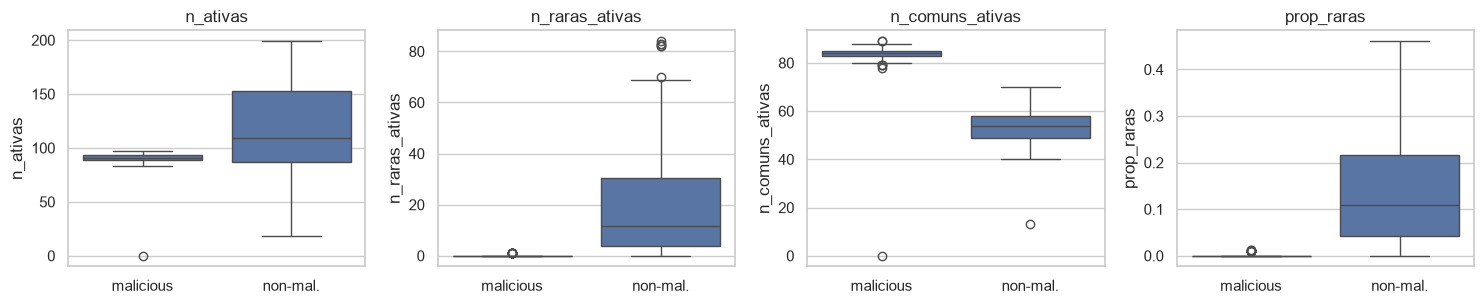

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, c in zip(axes, novas):
    sns.boxplot(x=y_train.map({0: 'non-mal.', 1: 'malicious'}), y=X_demo[c], ax=ax)
    ax.set_title(c); ax.set_xlabel('')
plt.tight_layout(); plt.show()

### 2.3 Resumir com PCA
Em vez de criar características à mão, o PCA junta as mais de 300 características em apenas 20 "resumos".

## 3. Comparar modelos
Treinamos cada modelo com 3 conjuntos de características:
- **A:** as características escolhidas
- **B:** A mais as 4 novas
- **C:** só os 20 resumos do PCA

Alguns modelos precisam que os valores estejam na mesma escala (Regressão Logística, kNN, SVM). Os outros não.

**Como medimos:** pelo F1 da classe mais pequena (`non-malicious`). O F1 é uma nota de 0 a 1 que junta "quantos encontrámos" e "quantos dos que dissemos estavam certos". Quanto mais perto de 1, melhor. Não usamos a percentagem de acertos porque engana quando uma classe é muito maior que a outra.

In [5]:
n_neg, n_pos = (y_train == 0).sum(), (y_train == 1).sum()

# (modelo, precisa de scaler?, só para dados binários?)
modelos = {
    'Logistic Regression': (LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE), True, False),
    'Decision Tree':       (DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE), False, False),
    'kNN (k=5)':           (KNeighborsClassifier(n_neighbors=5), True, False),
    'Gaussian NB':         (GaussianNB(), False, False),
    'Bernoulli NB':        (BernoulliNB(), False, True),
    'SVM (linear)':        (SVC(kernel='linear', class_weight='balanced', random_state=RANDOM_STATE), True, False),
    'SVM (RBF)':           (SVC(kernel='rbf', class_weight='balanced', random_state=RANDOM_STATE), True, False),
    'AdaBoost':            (AdaBoostClassifier(n_estimators=100, random_state=RANDOM_STATE), False, False),
    'Gradient Boosting':   (GradientBoostingClassifier(random_state=RANDOM_STATE), False, False),
    'XGBoost':             (XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, eval_metric='logloss',
                                          scale_pos_weight=n_neg / n_pos, random_state=RANDOM_STATE, n_jobs=-1), False, False),
    'Random Forest':       (RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1), False, False),
}

def montar(modelo, conjunto, escala):
    passos = [('sel', SelecionarFeatures())]
    if conjunto == 'B: Base + engineering':
        passos.append(('fe', AdicionarFeatures()))
    elif conjunto == 'C: PCA (20)':
        passos.append(('pca', PCA(n_components=20, random_state=RANDOM_STATE)))
    if escala:
        passos.append(('scaler', StandardScaler()))
    passos.append(('clf', modelo))
    return Pipeline(passos)

conjuntos = ['A: Base', 'B: Base + engineering', 'C: PCA (20)']

In [6]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    'f1_min':   make_scorer(f1_score, pos_label=0),
    'rec_min':  make_scorer(recall_score, pos_label=0),
    'prec_min': make_scorer(precision_score, pos_label=0, zero_division=0),
}

linhas = []
for nome, (modelo, escala, so_bin) in modelos.items():
    for conj in conjuntos:
        if so_bin and conj != 'A: Base':
            continue                       # Bernoulli NB só faz sentido com features binárias
        pipe = montar(modelo, conj, escala)
        r = cross_validate(pipe, X_train, y_train, cv=skf, scoring=scoring, n_jobs=-1)
        linhas.append({
            'modelo': nome, 'conjunto': conj,
            'F1 (min.)': r['test_f1_min'].mean(), 'desvio F1': r['test_f1_min'].std(),
            'Recall (min.)': r['test_rec_min'].mean(), 'Precision (min.)': r['test_prec_min'].mean(),
        })

res = pd.DataFrame(linhas)
print('Concluído:', len(res), 'combinações')

Concluído: 31 combinações


### 3.1 Resultados
Cada quadrado mostra a nota de um modelo com um conjunto de características. Mais alto = melhor.

conjunto,A: Base,B: Base + engineering,C: PCA (20)
modelo,,,
AdaBoost,0.953,0.991,0.973
SVM (RBF),0.991,0.991,0.963
Gaussian NB,0.991,0.991,0.983
XGBoost,0.945,0.983,0.983
Bernoulli NB,0.983,NaN,NaN
Decision Tree,0.967,0.982,0.983
Logistic Regression,0.983,0.983,0.983
SVM (linear),0.983,0.983,0.963
Random Forest,0.983,0.983,0.983


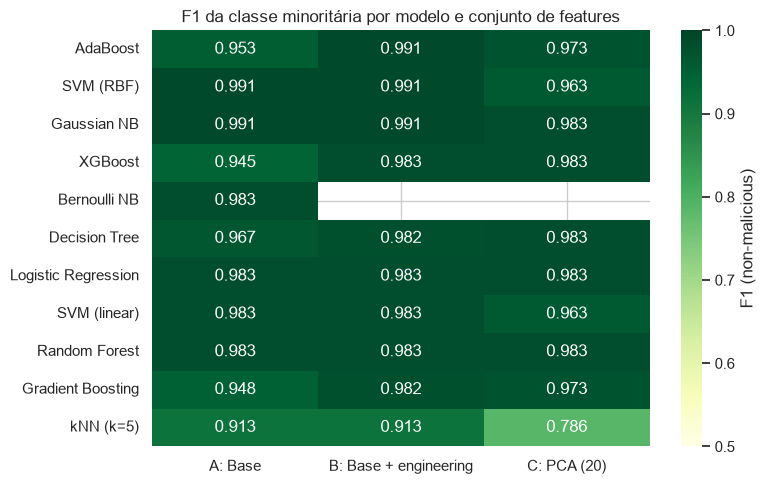

In [7]:
tabela = res.pivot(index='modelo', columns='conjunto', values='F1 (min.)')
tabela['melhor'] = tabela.max(axis=1)
tabela = tabela.sort_values('melhor', ascending=False).drop(columns='melhor')
display(tabela.round(3))

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(tabela, annot=True, fmt='.3f', cmap='YlGn', vmin=0.5, vmax=1, ax=ax, cbar_kws={'label': 'F1 (non-malicious)'})
ax.set_title('F1 da classe minoritária por modelo e conjunto de features'); ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout(); plt.show()

In [8]:
print('Tabela completa (ordenada por F1, depois por menor desvio):')
display(res.sort_values(['F1 (min.)', 'desvio F1'], ascending=[False, True]).round(3).reset_index(drop=True).head(15))

Tabela completa (ordenada por F1, depois por menor desvio):


,modelo,conjunto,F1 (min.),desvio F1,Recall (min.),Precision (min.)
0,Gaussian NB,A: Base,0.991,0.017,1.000,0.983
1,Gaussian NB,B: Base + engineering,0.991,0.017,1.000,0.983
2,SVM (RBF),A: Base,0.991,0.017,1.000,0.983
3,SVM (RBF),B: Base + engineering,0.991,0.017,1.000,0.983
4,AdaBoost,B: Base + engineering,0.991,0.017,1.000,0.983
5,XGBoost,B: Base + engineering,0.983,0.033,1.000,0.969
6,XGBoost,C: PCA (20),0.983,0.020,1.000,0.968
7,Logistic Regression,A: Base,0.983,0.021,0.983,0.983
8,Logistic Regression,B: Base + engineering,0.983,0.021,0.983,0.983
9,Logistic Regression,C: PCA (20),0.983,0.021,0.983,0.983


## 4. Testar o melhor
Escolhemos o melhor pelos resultados da validação cruzada (nunca pelo teste) e só depois o testamos, uma única vez.

Melhor combinação na CV: Gaussian NB | A: Base | F1 = 0.991

               precision    recall  f1-score   support

non-malicious       1.00      1.00      1.00        14
    malicious       1.00      1.00      1.00        61

     accuracy                           1.00        75
    macro avg       1.00      1.00      1.00        75
 weighted avg       1.00      1.00      1.00        75



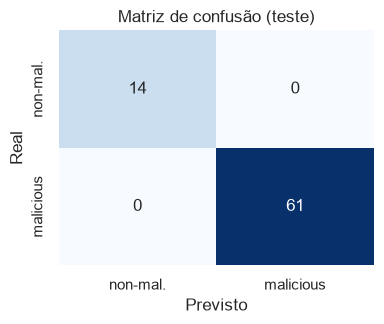

In [9]:
melhor = res.sort_values(['F1 (min.)', 'desvio F1'], ascending=[False, True]).iloc[0]
print('Melhor combinação na CV:', melhor['modelo'], '|', melhor['conjunto'], '| F1 =', round(melhor['F1 (min.)'], 3))

modelo, escala, _ = modelos[melhor['modelo']]
from sklearn.base import clone
final = montar(clone(modelo), melhor['conjunto'], escala).fit(X_train, y_train)
y_pred = final.predict(X_test)

print()
print(classification_report(y_test, y_pred, target_names=['non-malicious', 'malicious']))
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(4, 3.4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
            xticklabels=['non-mal.', 'malicious'], yticklabels=['non-mal.', 'malicious'])
ax.set_xlabel('Previsto'); ax.set_ylabel('Real'); ax.set_title('Matriz de confusão (teste)')
plt.tight_layout(); plt.show()

## 5. Que características importam?
Vemos quais as características que o Random Forest mais usou. As laranja são as que criámos.

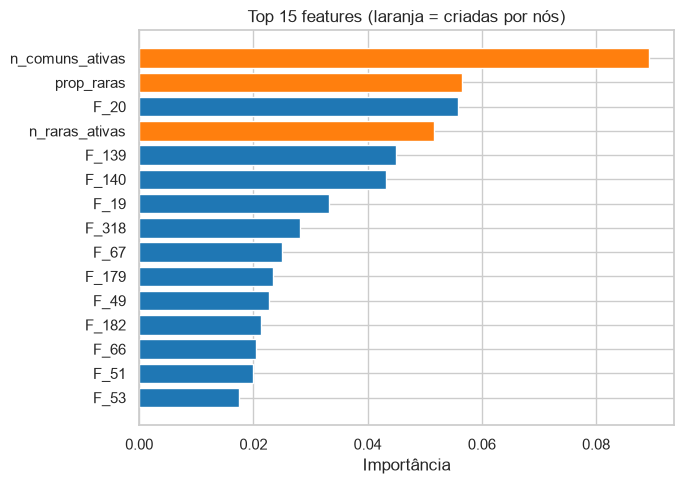

Posição das features criadas (em 392 features):
  n_ativas: posição 21, importância 0.0120
  n_raras_ativas: posição 4, importância 0.0517
  n_comuns_ativas: posição 1, importância 0.0892
  prop_raras: posição 2, importância 0.0566


In [10]:
pre = Pipeline([('sel', SelecionarFeatures()), ('fe', AdicionarFeatures())]).fit(X_train)
Xtr_b = pre.transform(X_train)

rf = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1).fit(Xtr_b, y_train)
imp = pd.Series(rf.feature_importances_, index=Xtr_b.columns).sort_values(ascending=False)

top = imp.head(15).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top.values, color=['tab:orange' if i in novas else 'tab:blue' for i in top.index])
ax.set_title('Top 15 features (laranja = criadas por nós)'); ax.set_xlabel('Importância')
plt.tight_layout(); plt.show()

print('Posição das features criadas (em', len(imp), 'features):')
for c in novas:
    print(f'  {c}: posição {list(imp.index).index(c) + 1}, importância {imp[c]:.4f}')

## 6. Conclusões
(Resultados desta execução.)

- Quase todos os modelos têm notas parecidas e boas. O kNN é o mais fraco.
- As características novas ajudaram sobretudo os modelos de árvores (Random Forest, XGBoost, AdaBoost, Gradient Boosting). Nos outros modelos não mudaram nada.
- Algumas das novas ficaram entre as mais importantes (`n_comuns_ativas` em 1.º lugar).
- O PCA não trouxe vantagem.
- No teste deu 100%, mas há poucas amostras de teste e as amostras `malicious` são muito parecidas entre si. Por isso, convém dar mais peso à validação cruzada.
- Diferenças pequenas entre modelos podem ser sorte e não um ganho real.
- Próximo passo: avaliar melhor os modelos (Módulo 7).